In [6]:
!pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://package-mirror.liara.ir/repository/pypi/simple
  Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
     ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
     ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
     ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
     ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
     ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
     ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
     ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
     ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
      --------------------------------------- 0.3/10.7 MB ? eta -:--:--
      --------------------------------------- 0.3/10.7 MB ? eta -:--:--
     - ------------------------------------- 0.5/10.7 MB 570.5 kB/s eta

## importing packages

In [10]:
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
import pandas as pd

## loading 'titanic' data set

In [25]:
sb.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [26]:
df = sb.load_dataset("titanic")
df.head(10)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


## چک کردن این که آیا NaN دارد یا خیر ؟

In [27]:
df.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

## چک کردن این که داده ها به چه مقدار یکتاست هست یا خیر

In [28]:
df.nunique()

survived         2
pclass           3
sex              2
age             88
sibsp            7
parch            7
fare           248
embarked         3
class            3
who              3
adult_male       2
deck             7
embark_town      3
alive            2
alone            2
dtype: int64

# چک کردن میزان حداکثر و حداقل مقادیر ویزگی ها 

In [29]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


 ## خصوصیات کلی دیتا ست

In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


## تغییر مقادیر دیتا تایپ ها 

In [36]:
df[["survived", "pclass", "sibsp", "parch"]]

,survived,pclass,sibsp,parch
0,0,3,1,0
1,1,1,1,0
2,1,3,0,0
3,1,1,1,0
4,0,3,0,0
...,...,...,...,...
886,0,2,0,0
887,1,1,0,0
888,0,3,1,2
889,1,1,0,0


In [42]:
for col in ["survived", "pclass", "sibsp", "parch"]:
    print(df[col].mean())

0.3838383838383838
2.308641975308642
0.5230078563411896
0.38159371492704824


In [45]:
for col in ["survived", "pclass", "sibsp", "parch"]:
    df[col] = df[col].astype(np.uint8)

In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    uint8   
 1   pclass       891 non-null    uint8   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    uint8   
 5   parch        891 non-null    uint8   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), str(5), uint8(4)
memory usage: 56.3 KB


## بررسی fare

In [58]:
df["fare"].index

RangeIndex(start=0, stop=891, step=1)

In [77]:
len(df)

891

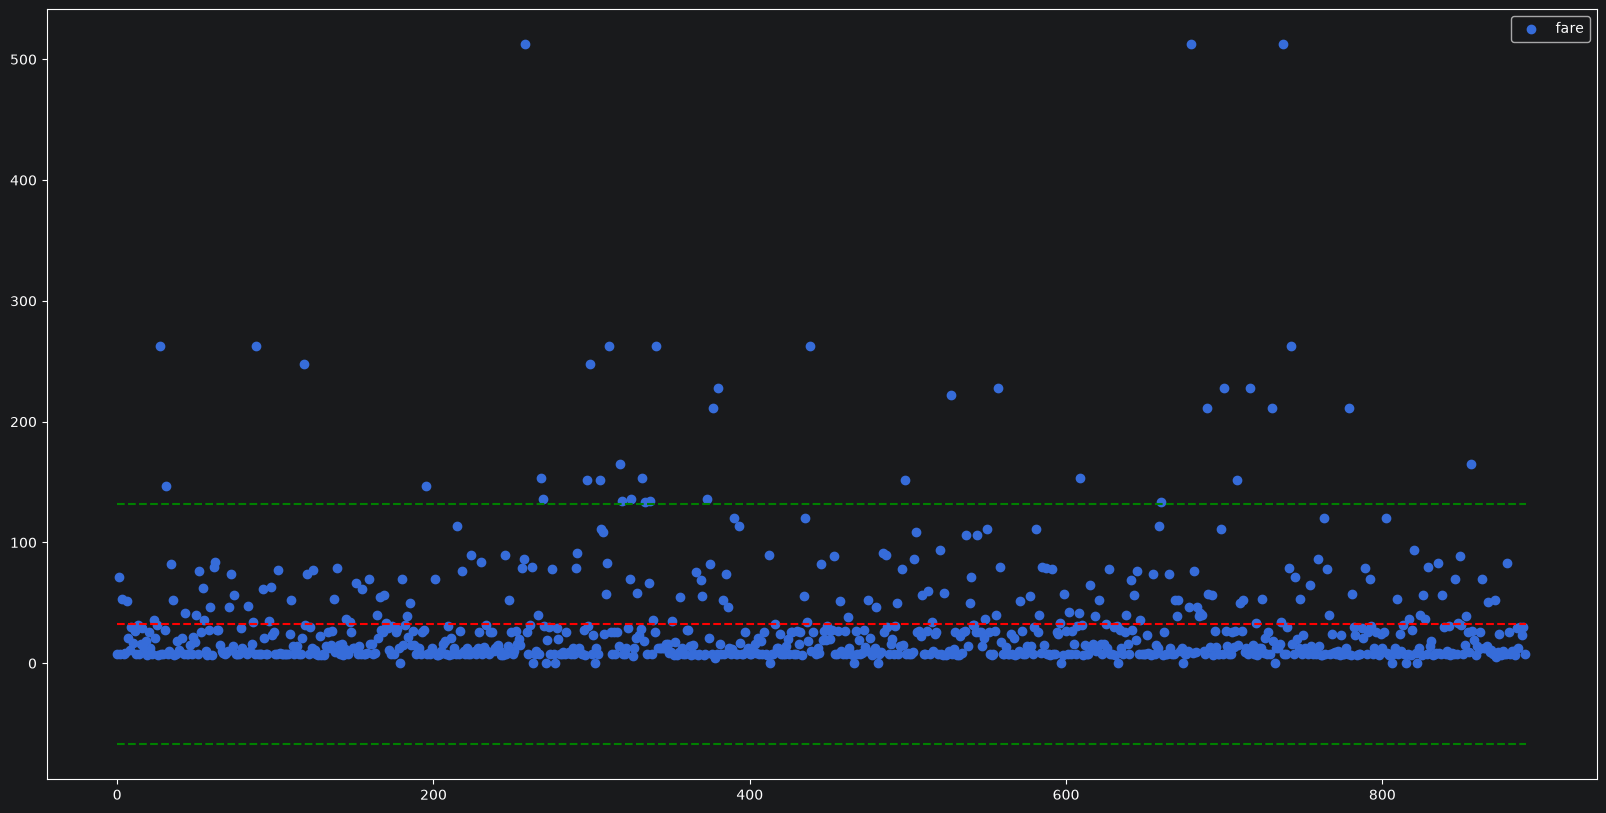

In [20]:
plt.figure(figsize=(20, 10))
plt.scatter(df["fare"].index, df["fare"], label="fare")

mean = df["fare"].mean()
std = df['fare'].std()
#  upper bond and lower bond
upper_bond = mean + std * 2
lower_bond = mean - std *2

plt.hlines(mean, xmin=0, xmax=len(df), colors="red", linestyles="dashed")

plt.hlines(upper_bond, xmin=0, xmax=len(df), colors="green", linestyles="dashed")

plt.hlines(lower_bond, xmin=0, xmax=len(df), colors="green", linestyles="dashed")

plt.legend(loc="upper right")
plt.show()

In [17]:
df['fare'].std()

np.float64(49.6934285971809)

## is we hav Nan number in "fare" ?

In [21]:
df['fare'].isna().sum()

np.int64(0)

## checking outlier in "fare"

In [30]:
df[(df["fare"] > upper_bond) | (df["fare"] < lower_bond)].head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
27,0,1,male,19.0,3,2,263.0000,S,First,man,True,C,Southampton,no,False
31,1,1,female,NaN,1,0,146.5208,C,First,woman,False,B,Cherbourg,yes,False
88,1,1,female,23.0,3,2,263.0000,S,First,woman,False,C,Southampton,yes,False
118,0,1,male,24.0,0,1,247.5208,C,First,man,True,B,Cherbourg,no,False
195,1,1,female,58.0,0,0,146.5208,C,First,woman,False,B,Cherbourg,yes,True


# age feature

## histogram show that most people were between 20-30 years old

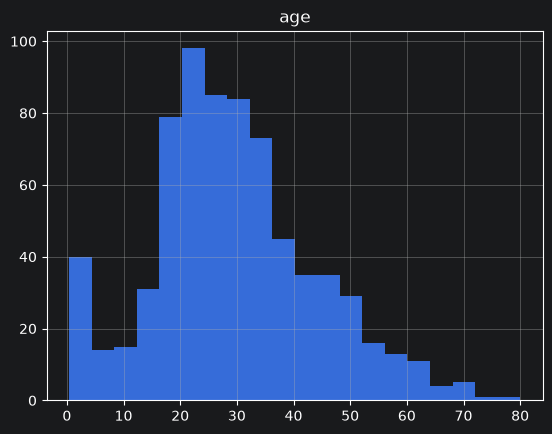

In [34]:
df.hist("age" , bins=20)
plt.show()